# 02 · Engenharia de features

Monta a matriz de features da **base da modelagem** (definida no 01: mais de 3 críticos,
lançados depois de 2009) e dos **jogos por lançar**, que são os alvos de previsão, como o
GTA VI. O resultado vai para `data/processed/features.parquet`, que o notebook de modelagem lê.

**Regra:** toda feature tem que poder ser calculada para um jogo que ainda não saiu. Daí:

- o histórico (nota anterior da desenvolvedora, da publisher e da série) só usa jogos lançados
  **antes** da data do jogo;
- ficam de fora as colunas que mudam depois do lançamento: `alt_names` (jogo famoso ganha
  apelidos), `game_status` (Delisted, Offline) e as notas de validação (`oc_*`, `mc_*`);
- `platforms` é o estado atual do IGDB e inclui ports feitos depois. A seção 4 trata o caso.

In [2]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_parquet(ROOT / "data/processed/games_scores.parquet")

MIN_CRITICS, MIN_YEAR = 4, 2010  # recorte do 01: mais de 3 críticos, lançados depois de 2009
TODAY = pd.Timestamp.today().normalize()

released = df[~df["is_upcoming"]]
base = released[(released["igdb_critic_n"] >= MIN_CRITICS) & (released["release_year"] >= MIN_YEAR)]
upcoming = df[df["is_upcoming"]]

games = pd.concat([base, upcoming]).set_index("igdb_id", drop=False)
# Data em que as features são calculadas. Por lançar sem data: tudo o que já saiu até hoje.
games["ref_date"] = games["first_release_date"].fillna(TODAY)
is_base = ~games["is_upcoming"]
feats = pd.DataFrame(index=games.index)

pd.set_option("display.max_columns", 50)
print(f"{len(games):,} jogos: {is_base.sum():,} na base, {(~is_base).sum():,} por lançar "
      f"({games.loc[~is_base, 'first_release_date'].isna().sum():,} sem data)")

10,345 jogos: 3,157 na base, 7,188 por lançar (5,936 sem data)


In [3]:
# Estilo dos gráficos: superfície clara, grade discreta, uma cor por papel
BLUE, BLUE_LIGHT, ORANGE = "#2a78d6", "#9ec5f4", "#eb6834"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "figure.figsize": (9, 4.2),
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.labelcolor": INK_2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "legend.frameon": False, "lines.linewidth": 2,
})

## 1. Histórico sem vazamento

Para cada jogo, os jogos anteriores da mesma desenvolvedora, da mesma publisher e da mesma série,
lançados **antes** da data do jogo. O histórico vem de todos os jogos lançados com
`MIN_CRITICS`+ críticos no IGDB, **de qualquer ano**: o GTA IV (2008) está fora da base, mas
informa o GTA V.

A exceção é a `pai_nota`, a nota do jogo original de um remake, remaster ou expansão. Quando o
original não tem `MIN_CRITICS`+ críticos no IGDB, vale a nota do OpenCritic (Top Critic
Average) ou, sem ela, o Metascore, ambos do Wikidata (`history_pool.parquet`). As duas passam
por uma conversão linear para a escala do IGDB, ajustada só com jogos lançados antes de
`CALIB_END` (o fim do treino no notebook 03), para que a conversão não aprenda nada da validação
nem do teste. É assim que o Ocarina of Time de 1998, sem nota no IGDB mas com 99 no Metacritic,
vira a `pai_nota` do remake.

Usar essas notas no histórico inteiro (desenvolvedora, publisher e série) foi testado e piorou:
entram cerca de 5 mil jogos menores, com poucos críticos no IGDB, que puxam as médias para baixo
(MAE do baseline de histórico na validação: 8,8 contra 8,2).

Três números por grupo:

- `*_n`: quantos jogos anteriores;
- `*_media`: média das notas, **encolhida** para a média global do momento. Com poucos jogos a
  média oscila muito, então ela é puxada para a média de todos os jogos lançados até a data, com
  peso de `HIST_K` jogos. Sem histórico, vale a média global;
- `*_ultima`: nota do jogo anterior mais recente (o "último da série").

A série junta franquia e coleção do IGDB e série do Wikidata, porque cada uma cobre buracos das
outras. Um jogo com várias desenvolvedoras soma o histórico de todas, sem contar o mesmo jogo
duas vezes.

In [4]:
HIST_K = 3  # peso da média global, em "jogos"

CALIB_END = "2022-01-01"  # fim do treino no 03: a conversão de escala só vê jogos anteriores

pool = pd.read_parquet(ROOT / "data/processed/history_pool.parquet").dropna(subset=["first_release_date"])
igdb_ok = pool["igdb_critic_n"] >= MIN_CRITICS
calib = pool[igdb_ok & (pool["first_release_date"] < CALIB_END)]
pool["nota_ref"] = pool["igdb_critic_score"].where(igdb_ok)
pool["fonte"] = pd.Series("IGDB", index=pool.index).where(igdb_ok)
for col, label in [("oc_top_avg", "OpenCritic"), ("mc_score", "Metacritic")]:
    pair = calib.dropna(subset=[col])
    slope, intercept = np.polyfit(pair[col], pair["igdb_critic_score"], 1)
    fill = pool["nota_ref"].isna() & pool[col].notna()
    pool.loc[fill, "nota_ref"] = intercept + slope * pool.loc[fill, col]
    pool.loc[fill, "fonte"] = label
    print(f"{label}: IGDB ≈ {intercept:.1f} + {slope:.2f} × nota ({len(pair):,} jogos na conversão)")
scored = pool.dropna(subset=["nota_ref"])  # nota de qualquer fonte: só para o jogo original
pool = scored[scored["fonte"] == "IGDB"]   # histórico: só nota do IGDB
print("jogos originais por fonte:", scored["fonte"].value_counts().to_dict())


def series_keys(frame):
    """Franquia, coleção (IGDB) e série (Wikidata) numa lista só, sem repetição."""
    names = frame[["franchises", "collections", "wd_series"]].fillna("").agg("|".join, axis=1)
    return names.str.lower().str.split("|").map(
        lambda xs: "|".join(sorted({x.strip() for x in xs if x.strip()})) or None)


games["series"] = series_keys(games)
pool = pool.assign(series=series_keys(pool))


def explode(frame, col):
    return frame.assign(**{col: frame[col].str.split("|")}).explode(col)


def history(col):
    """n, soma e última nota dos jogos do pool que dividem `col` e saíram antes de `ref_date`."""
    q = explode(games[["igdb_id", "ref_date", col]].dropna(subset=[col]), col)
    p = explode(pool[["igdb_id", "first_release_date", "nota_ref", col]].dropna(subset=[col]), col)
    m = q.merge(p, on=col, suffixes=("", "_prev"))
    m = (m[m["first_release_date"] < m["ref_date"]]
         .drop_duplicates(["igdb_id", "igdb_id_prev"])
         .sort_values("first_release_date"))
    return m.groupby("igdb_id")["nota_ref"].agg(n="size", soma="sum", ultima="last")


# Média global dos jogos lançados antes de cada data (o "prior" da média encolhida)
cum = pool.groupby("first_release_date")["nota_ref"].agg(["sum", "size"]).cumsum().reset_index()
prior = pd.merge_asof(games[["igdb_id", "ref_date"]].sort_values("ref_date"), cum,
                      left_on="ref_date", right_on="first_release_date", allow_exact_matches=False)
prior = (prior["sum"] / prior["size"]).set_axis(prior["igdb_id"]).reindex(games.index)

for col, prefix in [("developers", "dev"), ("publishers", "pub"), ("series", "serie")]:
    h = history(col).reindex(games.index)
    n = h["n"].fillna(0)
    feats[f"{prefix}_n"] = n
    feats[f"{prefix}_media"] = (h["soma"].fillna(0) + HIST_K * prior) / (n + HIST_K)
    feats[f"{prefix}_ultima"] = h["ultima"]

# Remake, remaster e expansão: a nota do jogo original, se ele saiu antes
parent = scored.set_index("igdb_id")
p_id = games["parent_game"]
feats["pai_nota"] = p_id.map(parent["nota_ref"]).where(
    p_id.map(parent["first_release_date"]) < games["ref_date"])

feats.loc[is_base].describe().T.round(1)  # até aqui, só o histórico

OpenCritic: IGDB ≈ 1.5 + 0.99 × nota (1,959 jogos na conversão)
Metacritic: IGDB ≈ 8.2 + 0.89 × nota (221 jogos na conversão)
jogos originais por fonte: {'OpenCritic': 5126, 'IGDB': 3776, 'Metacritic': 156}


,count,mean,std,min,25%,50%,75%,max
dev_n,3157.0,4.5,7.2,0.0,0.0,2.0,6.0,57.0
dev_media,3157.0,74.3,3.1,59.7,73.2,73.7,76.0,87.6
dev_ultima,2030.0,75.4,10.7,16.2,69.8,77.2,82.8,97.6
pub_n,3157.0,40.7,51.5,0.0,2.0,20.0,62.0,311.0
pub_media,3157.0,74.2,3.1,59.5,72.4,74.1,76.3,83.9
pub_ultima,2685.0,75.1,11.0,16.2,69.5,76.8,82.7,97.6
serie_n,3157.0,4.5,10.7,0.0,0.0,0.0,4.0,195.0
serie_media,3157.0,74.3,2.9,59.0,73.3,73.6,75.4,84.7
serie_ultima,1543.0,76.4,10.4,32.2,70.3,78.0,83.8,97.4
pai_nota,183.0,81.0,9.3,45.8,74.8,82.5,88.0,96.0


Conferência com os jogos da Rockstar: o histórico de cada um só pode conter o que saiu antes
dele.

In [5]:
rockstar = ["red-dead-redemption", "grand-theft-auto-v", "red-dead-redemption-2", "grand-theft-auto-vi"]
check = games.reset_index(drop=True).set_index("slug").loc[rockstar, ["igdb_id", "release_year", "igdb_critic_score"]]
check.join(feats, on="igdb_id").drop(columns="igdb_id").round(1)

,release_year,igdb_critic_score,dev_n,dev_media,dev_ultima,pub_n,pub_media,pub_ultima,serie_n,serie_media,serie_ultima,pai_nota
slug,,,,,,,,,,,,
red-dead-redemption,2010,91.8,8.0,81.0,89.0,18.0,80.0,73.8,1.0,71.6,66.0,NaN
grand-theft-auto-v,2013,88.1,7.0,85.7,89.4,25.0,80.2,76.7,4.0,83.6,89.0,NaN
red-dead-redemption-2,2018,94.1,2.0,75.8,83.8,31.0,80.1,83.8,3.0,78.0,90.0,NaN
grand-theft-auto-vi,2026,NaN,3.0,79.4,94.1,34.0,80.1,86.7,5.0,84.5,88.1,NaN


## 2. Hype

`hypes` é o número de follows no IGDB antes do lançamento. Três cuidados:

- **escala:** cresce em ordens de grandeza, então entra em log;
- **ausente não é zero:** o IGDB começou a contar por volta de 2013, então jogos antigos não têm o
  valor. Fica `NaN`, com uma flag;
- **inflação:** a base de usuários do IGDB cresceu, e 100 hypes em 2014 não equivalem a 100 em
  2025. `hype_pct_ano` é o percentil do jogo entre os jogos do mesmo ano com hype (todos os do
  dataset, não só os da base).

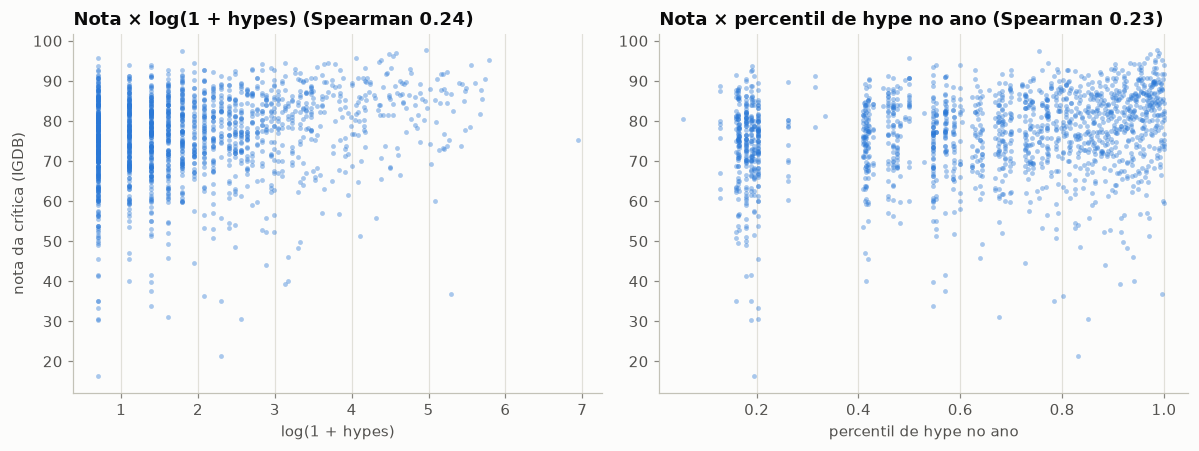

base com hype: 1,655 de 3,157


In [6]:
hyped = df.loc[df["hypes"] > 0, ["igdb_id", "release_year", "hypes"]]
pct = hyped.groupby("release_year")["hypes"].rank(pct=True).set_axis(hyped["igdb_id"])

feats["hype_log"] = np.log1p(games["hypes"])
feats["hype_ausente"] = games["hypes"].isna().astype("int8")
feats["hype_pct_ano"] = games["igdb_id"].map(pct)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
hb = games[is_base & games["hypes"].notna()]
for ax, col, label in [(axes[0], "hype_log", "log(1 + hypes)"),
                       (axes[1], "hype_pct_ano", "percentil de hype no ano")]:
    ax.scatter(feats.loc[hb.index, col], hb["igdb_critic_score"], s=10, color=BLUE, alpha=0.4, linewidths=0)
    rho = feats.loc[hb.index, col].corr(hb["igdb_critic_score"], method="spearman")
    ax.set_title(f"Nota × {label} (Spearman {rho:.2f})")
    ax.set_xlabel(label); ax.grid(axis="both")
axes[0].set_ylabel("nota da crítica (IGDB)")
plt.tight_layout(); plt.show()
print(f"base com hype: {len(hb):,} de {is_base.sum():,}")

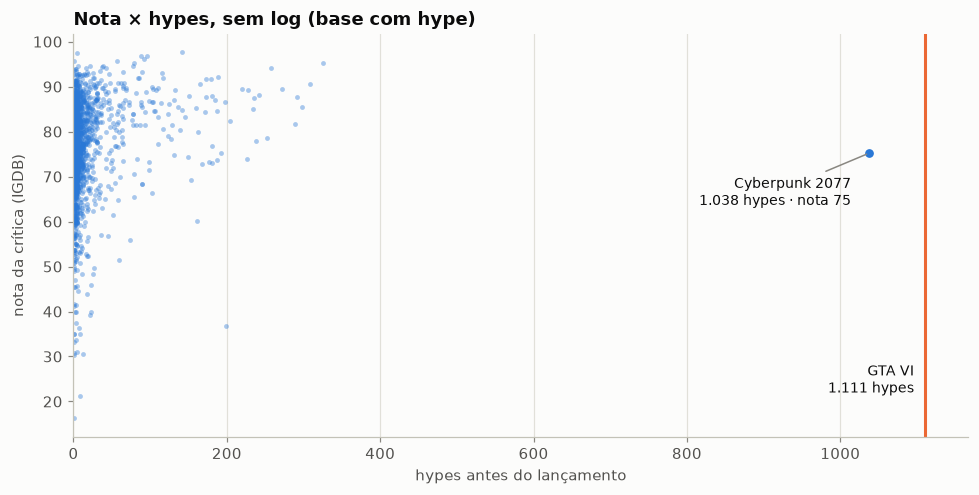

base com hype: 1,655 | menos de 100 hypes: 96% | mediana: 4 hypes


In [7]:
# Mesmo hype sem log: quase todos os jogos ficam espremidos perto de zero
gta6_hypes = games.loc[games["slug"] == "grand-theft-auto-vi", "hypes"].iloc[0]
top = hb.loc[hb["hypes"].idxmax()]  # o jogo da base mais próximo do GTA VI

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(hb["hypes"], hb["igdb_critic_score"], s=10, color=BLUE, alpha=0.4, linewidths=0)
ax.axvline(gta6_hypes, color=ORANGE, linewidth=2)
ax.text(gta6_hypes - 15, 22, f"GTA VI\n{gta6_hypes:,.0f} hypes".replace(",", "."), color=INK, fontsize=9, ha="right")
ax.scatter([top["hypes"]], [top["igdb_critic_score"]], s=60, color=BLUE, edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.annotate(f"{top['name']}\n{top['hypes']:,.0f} hypes · nota {top['igdb_critic_score']:.0f}".replace(",", "."),
            (top["hypes"], top["igdb_critic_score"]), xytext=(-12, -34), textcoords="offset points",
            ha="right", fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=1))
ax.set_xlim(0, gta6_hypes * 1.05); ax.grid(axis="both")
ax.set_xlabel("hypes antes do lançamento"); ax.set_ylabel("nota da crítica (IGDB)")
ax.set_title("Nota × hypes, sem log (base com hype)")
plt.tight_layout(); plt.show()

print(f"base com hype: {len(hb):,} | menos de 100 hypes: {(hb['hypes'] < 100).mean():.0%} | "
      f"mediana: {hb['hypes'].median():.0f} hypes")

In [8]:
# Os 15 jogos já lançados em 2026 com mais hype, contra GTA VI e o remake de Ocarina of Time (por lançar).
# A posição no ano conta todos os jogos de 2026 com hype, lançados ou não; * = menos de MIN_CRITICS críticos.
y26 = df[(df["release_year"] == 2026) & (df["hypes"] > 0)]
rank_ano = y26["hypes"].rank(ascending=False, method="min")
refs = df[df["slug"].isin(["grand-theft-auto-vi", "the-legend-of-zelda-ocarina-of-time--1"])].sort_values("hypes", ascending=False)
t26 = pd.concat([y26[~y26["is_upcoming"]].nlargest(15, "hypes"), refs])

pd.DataFrame({
    "posição no ano": rank_ano.loc[t26.index].astype(int),
    "jogo": t26["name"] + np.where(t26["game_type"] == "Remake", " (remake)", ""),
    "lançamento": t26["first_release_date"].dt.strftime("%d/%m") + np.where(t26["is_upcoming"], " (por lançar)", ""),
    "hypes": t26["hypes"].astype(int),
    "GTA VI tem × mais": (gta6_hypes / t26["hypes"]).round(1).mask(t26["slug"] == "grand-theft-auto-vi"),
    "percentil no ano": t26["igdb_id"].map(pct).round(3),
    "nota IGDB": [f"{s:.1f}" + ("*" if n < MIN_CRITICS else "") if pd.notna(s) else "—"
                  for s, n in zip(t26["igdb_critic_score"], t26["igdb_critic_n"])],
    "críticos": t26["igdb_critic_n"].astype("Int64"),
    "OpenCritic": t26["oc_top_avg"].round(0).astype("Int64"),
}).set_index("posição no ano")


,jogo,lançamento,hypes,GTA VI tem × mais,percentil no ano,nota IGDB,críticos,OpenCritic
posição no ano,,,,,,,,
2,Resident Evil Requiem,27/02,309,3.6,0.999,90.5,6,89
3,Crimson Desert Enhanced,19/03,298,3.7,0.998,85.5,4,79
4,Marvel's Wolverine,15/09,292,3.8,0.997,87.8,4,76
5,007 First Light,27/05,289,3.8,0.996,81.7,6,87
6,The Blood of Dawnwalker,03/09,272,4.1,0.995,89.5,4,83
7,Control Resonant,24/09,242,4.6,0.994,88.2,5,83
8,Pragmata,17/04,236,4.7,0.993,87.5,6,86
10,Onimusha: Way of the Sword,04/09,187,5.9,0.991,84.5,4,85
11,Replaced,14/04,142,7.8,0.990,95.0*,1,77


## 3. Conteúdo: gêneros, temas, modos e perspectiva

Listas viram colunas 0/1 (multi-hot). Categorias com menos de `MIN_CAT` jogos na base ficam de
fora: não há exemplos para o modelo aprender um efeito.

In [7]:
MIN_CAT = 30


def slug(s):
    return re.sub(r"[^0-9a-z]+", "_", s.lower()).strip("_")


def multi_hot(values, prefix):
    d = values.str.get_dummies("|")
    d = d.loc[:, d[is_base].sum() >= MIN_CAT]
    return d.rename(columns=lambda c: f"{prefix}_{slug(c)}").astype("int8")


content = pd.concat([
    multi_hot(games["genres"], "genero"),
    multi_hot(games["themes"], "tema"),
    multi_hot(games["game_modes"], "modo"),
    multi_hot(games["perspectives"], "perspectiva"),
    multi_hot(games["game_type"], "tipo"),
], axis=1)
feats = feats.join(content)
print(f"{content.shape[1]} colunas:", ", ".join(content.columns))

53 colunas: genero_adventure, genero_arcade, genero_card_board_game, genero_fighting, genero_hack_and_slash_beat_em_up, genero_indie, genero_music, genero_platform, genero_point_and_click, genero_puzzle, genero_racing, genero_real_time_strategy_rts, genero_role_playing_rpg, genero_shooter, genero_simulator, genero_sport, genero_strategy, genero_tactical, genero_turn_based_strategy_tbs, genero_visual_novel, tema_action, tema_business, tema_comedy, tema_drama, tema_fantasy, tema_historical, tema_horror, tema_kids, tema_mystery, tema_non_fiction, tema_open_world, tema_party, tema_sandbox, tema_science_fiction, tema_stealth, tema_survival, tema_thriller, tema_warfare, modo_co_operative, modo_massively_multiplayer_online_mmo, modo_multiplayer, modo_single_player, modo_split_screen, perspectiva_bird_view_isometric, perspectiva_first_person, perspectiva_side_view, perspectiva_text, perspectiva_third_person, perspectiva_virtual_reality, tipo_expanded_game, tipo_main_game, tipo_remake, tipo_rem

## 4. Plataformas

`platforms` é o estado **atual** do IGDB: o GTA V (2013) aparece com PS5 e Xbox Series X/S, que
receberam o port em 2022. Jogo bem avaliado ganha mais ports, então usar a lista crua vaza o
resultado.

A correção possível com estes dados: tirar as plataformas **lançadas depois do jogo**, que só
podem ser ports. Ports para plataformas que já existiam (o GTA V no PC, em 2015) continuam
indetectáveis. Por isso as features ficam no nível de família (PC, PlayStation, Xbox...) e o
número de plataformas fica de fora, porque é o que mais cresce com ports.

In [8]:
# Lançamento dos consoles e headsets desde 2005, com nome e abreviação do IGDB
PLATFORM_LAUNCH = {
    ("Xbox 360", "X360"): "2005-11-22", ("PlayStation 3", "PS3"): "2006-11-11", ("Wii",): "2006-11-19",
    ("Nintendo 3DS", "3DS"): "2011-02-26", ("PlayStation Vita", "Vita"): "2011-12-17",
    ("Wii U", "WiiU"): "2012-11-18", ("PlayStation 4", "PS4"): "2013-11-15", ("Xbox One", "XONE"): "2013-11-22",
    ("PlayStation VR", "PSVR"): "2016-10-13", ("Nintendo Switch", "Switch"): "2017-03-03",
    ("Google Stadia", "Stadia"): "2019-11-19", ("Meta Quest 2",): "2020-10-13",
    ("Xbox Series X/S", "Series X/S"): "2020-11-10", ("PlayStation 5", "PS5"): "2020-11-12",
    ("PlayStation VR2", "PSVR2"): "2023-02-22", ("Meta Quest 3",): "2023-10-10",
    ("Nintendo Switch 2", "Switch 2"): "2025-06-05",
}
PLATFORM_LAUNCH = {name: pd.Timestamp(d) for names, d in PLATFORM_LAUNCH.items() for name in names}
FAMILIES = {
    "pc": r"^(?:PC \(Microsoft Windows\)|PC|Mac|Linux)$",
    "playstation": r"PlayStation|^PS",
    "xbox": r"Xbox|XBOX|^XONE$|^X360$|^Series X/S$",
    "nintendo": r"Nintendo|Wii|Switch|3DS|NDS|NGC|Game Boy|GBA",
    "mobile": r"^(?:iOS|Android|Mobile|Legacy Mobile Device|Windows Phone|Win Phone)$",
    "vr": r"VR|Quest|Oculus|Rift",
}

plat = explode(games[["igdb_id", "ref_date", "platforms"]].dropna(subset=["platforms"]), "platforms")
is_port = plat["platforms"].map(PLATFORM_LAUNCH) > plat["ref_date"]
plat = plat[~is_port]
for fam, rx in FAMILIES.items():
    feats[f"plat_{fam}"] = (plat["platforms"].str.contains(rx).groupby(plat["igdb_id"]).any()
                            .reindex(games.index, fill_value=False).astype("int8"))

ports = is_port.groupby(explode(games[["igdb_id", "platforms"]].dropna(), "platforms")["igdb_id"]).any()
print(f"jogos da base com ao menos um port removido: {ports.reindex(games.index[is_base], fill_value=False).sum():,}")
feats.loc[games["slug"].isin(["grand-theft-auto-v", "grand-theft-auto-vi"]).values,
          [c for c in feats.columns if c.startswith("plat_")]].set_axis(["GTA V", "GTA VI"])

jogos da base com ao menos um port removido: 796


,plat_pc,plat_playstation,plat_xbox,plat_nintendo,plat_mobile,plat_vr
GTA V,1,1,1,0,0,0
GTA VI,0,1,1,0,0,0


## 5. Produção: engine, país, classificação etária e data

- **engine:** Unity e Unreal (todas as versões) têm volume; o resto vira "outra", e a ausência
  ganha flag própria;
- **país** (Wikidata): multi-hot com o mesmo `MIN_CAT`; England, Scotland e Wales contam como
  United Kingdom;
- **classificação etária:** a idade mínima em anos, do ESRB e, se não houver, do PEGI. Sai antes
  do lançamento;
- **data:** ano (tendência da nota no tempo), mês e flag do quarto trimestre (temporada de festas).

In [9]:
eng = games["engines"].fillna("")
feats["engine_unity"] = eng.str.contains("Unity").astype("int8")
feats["engine_unreal"] = eng.str.contains("Unreal").astype("int8")
feats["engine_ausente"] = (eng == "").astype("int8")

country = games["wd_country"].str.replace(r"\b(?:England|Scotland|Wales)\b", "United Kingdom", regex=True)
country = country.str.split("|").map(lambda xs: "|".join(sorted(set(xs))), na_action="ignore")
feats = feats.join(multi_hot(country, "pais"))

ESRB_AGE = {"Everyone": 6, "Everyone 10+": 10, "Teen": 13, "Mature 17+": 17, "Adults Only 18+": 18}
PEGI_AGE = {"PEGI 3": 3, "PEGI 7": 7, "PEGI 12": 12, "PEGI 16": 16, "PEGI 18": 18}


def max_age(values, table):
    return explode(values.dropna().to_frame("r"), "r")["r"].map(table).groupby(level=0).max()


feats["idade_minima"] = (max_age(games["wd_esrb"], ESRB_AGE)
                         .combine_first(max_age(games["wd_pegi"], PEGI_AGE)).reindex(games.index))

feats["ano"] = games["release_year"].astype("float")
feats["mes"] = games["first_release_date"].dt.month.astype("float")
feats["q4"] = (feats["mes"] >= 10).astype("int8").where(feats["mes"].notna())

feats.loc[is_base, ["engine_unity", "engine_unreal", "engine_ausente", "idade_minima", "q4"]].agg(["mean", "count"]).round(2)

,engine_unity,engine_unreal,engine_ausente,idade_minima,q4
mean,0.19,0.18,0.37,12.24,0.28
count,3157.00,3157.00,3157.00,2398.00,3157.00


## 6. Matriz final

Preenchimento, relação de cada feature com a nota na base e o vetor do GTA VI.

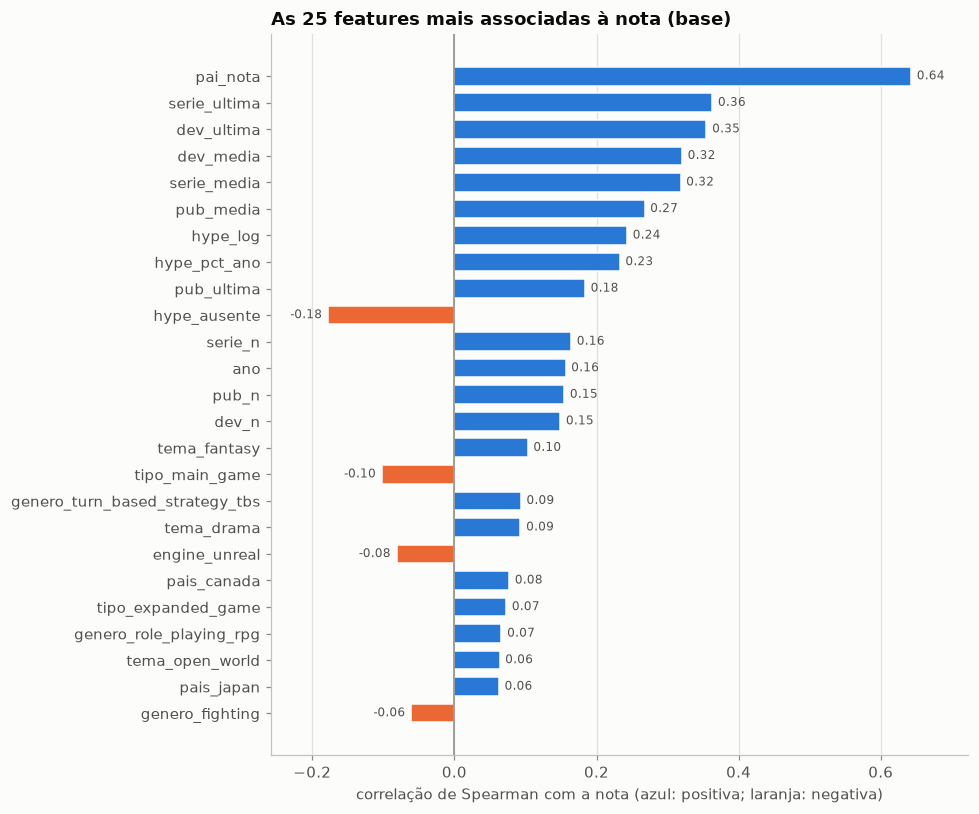

In [10]:
y = games.loc[is_base, "igdb_critic_score"]
X = feats.loc[is_base]
rho = X.corrwith(y, method="spearman").dropna()
top = rho.reindex(rho.abs().sort_values().index)[-25:]

fig, ax = plt.subplots(figsize=(9, 7.5))
colors = np.where(top > 0, BLUE, ORANGE)
ax.barh(top.index, top.values, color=colors, height=0.7, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(0, color=MUTED, linewidth=1)
for yy, v in enumerate(top.values):
    ax.text(v + (0.008 if v > 0 else -0.008), yy, f"{v:.2f}", va="center", fontsize=8, color=INK_2,
            ha="left" if v > 0 else "right")
ax.set_xlim(top.min() - 0.08 if top.min() < 0 else 0, top.max() + 0.08)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("correlação de Spearman com a nota (azul: positiva; laranja: negativa)")
ax.set_title("As 25 features mais associadas à nota (base)")
plt.tight_layout(); plt.show()

O histórico é o candidato mais forte. Os gráficos abaixo comparam a média encolhida da
desenvolvedora e a nota do último jogo da série com a nota do jogo, só para quem tem histórico. A
linha laranja marca o valor do GTA VI.

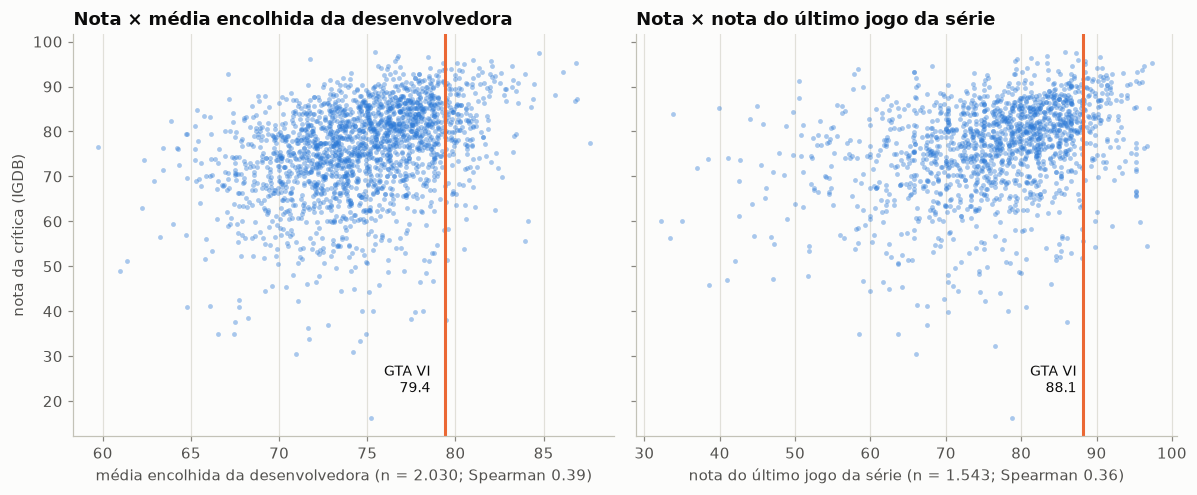

In [11]:
gta6 = games.index[games["slug"] == "grand-theft-auto-vi"][0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, col, n_col, label in [(axes[0], "dev_media", "dev_n", "média encolhida da desenvolvedora"),
                              (axes[1], "serie_ultima", "serie_n", "nota do último jogo da série")]:
    has = X[n_col] > 0
    ax.scatter(X.loc[has, col], y[has], s=10, color=BLUE, alpha=0.4, linewidths=0)
    ax.axvline(feats.loc[gta6, col], color=ORANGE, linewidth=2)
    ax.text(feats.loc[gta6, col] - 0.8, 22, f"GTA VI\n{feats.loc[gta6, col]:.1f}", color=INK, fontsize=9, ha="right")
    r = X.loc[has, col].corr(y[has], method="spearman")
    ax.set_title(f"Nota × {label}")
    ax.set_xlabel(f"{label} (n = {has.sum():,}; Spearman {r:.2f})".replace(",", "."))
    ax.grid(axis="both")
axes[0].set_ylabel("nota da crítica (IGDB)")
plt.tight_layout(); plt.show()

In [12]:
print(f"{feats.shape[1]} features | colunas com ausentes na base:")
display(feats.loc[is_base].isna().mean().loc[lambda s: s > 0].sort_values(ascending=False).round(2).to_frame("ausente"))

feats.loc[[gta6]].T.rename(columns={gta6: "GTA VI"}).query("`GTA VI` != 0")

91 features | colunas com ausentes na base:


,ausente
pai_nota,0.94
serie_ultima,0.51
hype_log,0.48
hype_pct_ano,0.48
dev_ultima,0.36
idade_minima,0.24
pub_ultima,0.15


igdb_id,GTA VI
dev_n,3.000000
dev_media,79.379815
dev_ultima,94.058824
pub_n,34.000000
pub_media,80.085619
pub_ultima,86.700000
serie_n,5.000000
serie_media,84.484482
serie_ultima,88.137931
pai_nota,NaN


### Salvar

Uma linha por jogo (base e por lançar), com identificação, target e features. O target fica
vazio nos jogos por lançar.

In [13]:
ID_COLS = ["igdb_id", "name", "slug", "first_release_date", "release_year", "is_upcoming",
           "igdb_critic_score", "igdb_critic_n"]
out = games[ID_COLS].join(feats).reset_index(drop=True)
out.to_parquet(ROOT / "data/processed/features.parquet", index=False)
print(f"{out.shape[0]:,} jogos × {feats.shape[1]} features -> data/processed/features.parquet")

10,345 jogos × 91 features -> data/processed/features.parquet


## 7. Multicolinearidade (VIF)

O VIF de uma feature mede quanto ela é explicada pelas outras: é `1 / (1 - R²)` da regressão
dela (com intercepto) contra todas as demais. VIF 1 é independência; acima de 5 a colinearidade
já infla a variância dos coeficientes de um modelo linear; acima de 10 é grave.

Importa para **Ridge e regressão linear** (coeficientes instáveis, sinais trocados) e para a
**interpretação** (o SHAP divide o crédito entre features redundantes de forma arbitrária). Não
atrapalha a previsão do LightGBM.

O VIF exige a matriz sem ausentes. A imputação principal preenche cada ausente com o melhor
palpite disponível: sem histórico, a última nota vira a média encolhida (o melhor palpite sem jogo anterior) e o jogo
original vira a média da série; sem hype, 0 (a flag `hype_ausente` marca o caso); o resto, a
mediana. A coluna `vif_mediana` repete a conta imputando tudo pela mediana, para ver se o
diagnóstico depende dessa escolha. A matriz que os modelos lineares usam de fato é conferida na
seção 8.

In [14]:
def impute_linear(X):
    X = X.copy()
    for p in ["dev", "pub", "serie"]:
        X[f"{p}_ultima"] = X[f"{p}_ultima"].fillna(X[f"{p}_media"])
    X["pai_nota"] = X["pai_nota"].fillna(X["serie_media"])
    X[["hype_log", "hype_pct_ano"]] = X[["hype_log", "hype_pct_ano"]].fillna(0)
    return X.fillna(X.median())


def vif(X):
    """VIF de cada coluna: 1 / (1 - R²) da regressão dela, com intercepto, contra as outras."""
    Z = X.to_numpy(float)
    out = {}
    for j, c in enumerate(X.columns):
        target = Z[:, j]
        A = np.column_stack([np.ones(len(Z)), np.delete(Z, j, axis=1)])
        resid = target - A @ np.linalg.lstsq(A, target, rcond=None)[0]
        r2 = 1 - resid @ resid / ((target - target.mean()) @ (target - target.mean()))
        out[c] = np.inf if r2 > 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out)


Xl = impute_linear(X)
corr = Xl.corr().abs().mask(np.eye(Xl.shape[1], dtype=bool), 0)
vifs = pd.DataFrame({
    "vif": vif(Xl), "vif_mediana": vif(X.fillna(X.median())),
    "mais_correlacionada": corr.idxmax(), "r": corr.max(),
}).sort_values("vif", ascending=False)
print(f"{len(vifs)} features | VIF >= 5: {(vifs['vif'] >= 5).sum()} | VIF >= 10: {(vifs['vif'] >= 10).sum()}")
vifs[vifs["vif"] >= 3].round(2)

91 features | VIF >= 5: 4 | VIF >= 10: 3


,vif,vif_mediana,mais_correlacionada,r
hype_pct_ano,15.49,4.65,hype_log,0.94
tipo_main_game,12.63,11.87,tipo_remaster,0.55
hype_log,11.73,5.30,hype_pct_ano,0.94
tipo_remaster,5.11,5.08,tipo_main_game,0.55
tipo_expanded_game,4.93,4.86,tipo_main_game,0.53
tipo_remake,4.89,4.76,tipo_main_game,0.52
serie_media,4.52,2.14,pai_nota,0.83
pai_nota,4.12,1.11,serie_media,0.83
hype_ausente,4.05,2.10,hype_pct_ano,0.84
perspectiva_virtual_reality,3.44,3.45,plat_vr,0.83


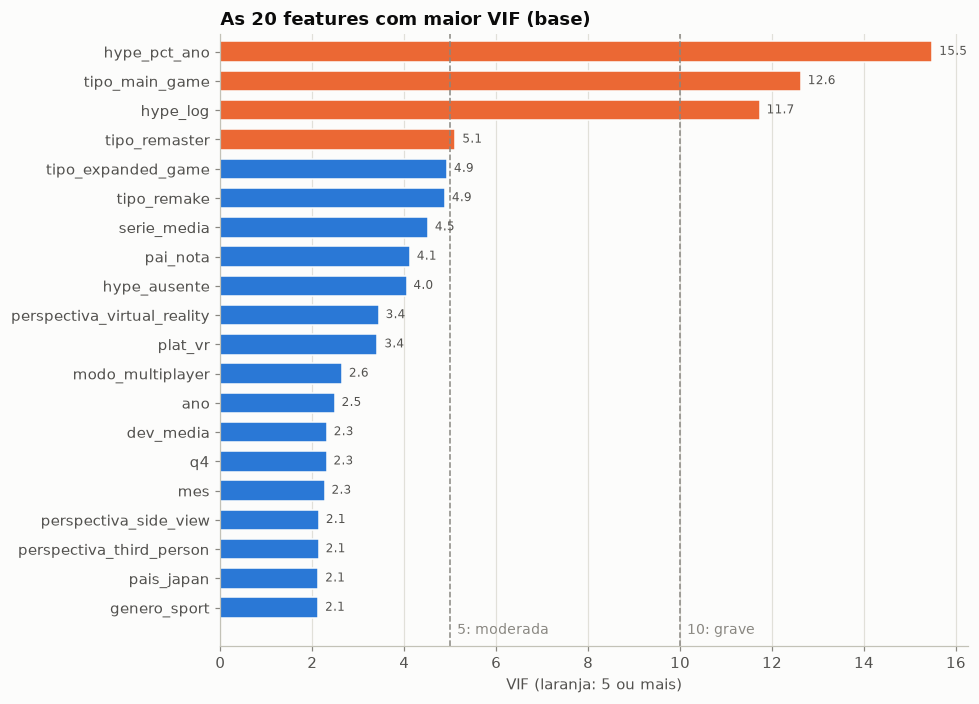

,,|r|
hype_log,hype_pct_ano,0.94
hype_ausente,hype_pct_ano,0.84
perspectiva_virtual_reality,plat_vr,0.83
serie_media,pai_nota,0.83
hype_log,hype_ausente,0.75
mes,q4,0.73


In [15]:
top = vifs["vif"].head(20)[::-1]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top.values, color=np.where(top >= 5, ORANGE, BLUE), height=0.7,
        edgecolor="#fcfcfb", linewidth=1)
for limit, label in [(5, "5: moderada"), (10, "10: grave")]:
    ax.axvline(limit, color=MUTED, linewidth=1, linestyle="--")
    ax.text(limit + 0.15, -0.9, label, color=MUTED, fontsize=9)
for yy, v in enumerate(top.values):
    ax.text(v + 0.15, yy, f"{v:.1f}", va="center", fontsize=8, color=INK_2)
ax.set_ylim(-1.3, len(top) - 0.4)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("VIF (laranja: 5 ou mais)")
ax.set_title("As 20 features com maior VIF (base)")
plt.tight_layout(); plt.show()

# Pares com correlação forte, para localizar a origem de cada VIF alto
upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)
corr.where(upper).stack().loc[lambda s: s >= 0.7].sort_values(ascending=False).round(2).to_frame("|r|")

### Diagnóstico

Há **dois casos de multicolinearidade**. O das dummies não depende da imputação; o do hype
enfraquece com a mediana (VIF 5,3 e 4,7), porque ela preenche os 48% sem hype com um valor do
meio, mas continua no limite:

1. **`hype_log` × `hype_pct_ano`** (correlação 0,94; VIF 11,8 e 15,5). São duas medidas do mesmo
   hype. `hype_ausente` acompanha (VIF 4), porque os dois valem 0 quando falta hype. Fica o
   **percentil**: ele corrige o crescimento do IGDB e é limitado entre 0 e 1. Já o `hype_log` do
   GTA VI (7,0) passa do maior valor da base (Cyberpunk 2077, 6,9), e um modelo linear estaria
   extrapolando.
2. **`tipo_*`** (VIF de 12,8 em `tipo_main_game`). É a armadilha das dummies: os tipos somam
   quase 1 em todo jogo (só Standalone Expansion ficou fora, por ter menos de `MIN_CAT` jogos).
   Sai **`tipo_main_game`**, que vira a categoria de referência.

Pares moderados, abaixo de 5, que podem ficar:

- `serie_media` × `pai_nota` (r = 0,85, VIF 5,0 e 4,7): remake e remaster são da mesma série do
  original. Isso vem da imputação: com a mediana, os dois ficam abaixo de 2;
- `plat_vr` × `perspectiva_virtual_reality` (r = 0,83, VIF 3,4): quase a mesma informação, mas
  ambas raras;
- `mes` × `q4` (r = 0,73, VIF 2,3): o trimestre é um recorte do mês. Ficam as duas, porque o
  mês sozinho não captura o salto de fim de ano num modelo linear.

Histórico da desenvolvedora, da publisher e da série **não** é redundante: as correlações entre
os grupos ficam entre 0,25 e 0,45, e média e última nota do mesmo grupo, em 0,65.

In [16]:
LINEAR_DROP = ["hype_log", "tipo_main_game"]  # para modelos lineares; o LightGBM pode usar tudo

after = vif(Xl.drop(columns=LINEAR_DROP)).sort_values(ascending=False)
print(f"depois de remover {LINEAR_DROP}: VIF máximo {after.max():.1f} ({after.idxmax()}), "
      f"{(after >= 5).sum()} features com VIF >= 5")
after.head(8).round(2).to_frame("vif")

depois de remover ['hype_log', 'tipo_main_game']: VIF máximo 4.4 (serie_media), 0 features com VIF >= 5


,vif
serie_media,4.39
hype_pct_ano,4.25
pai_nota,3.87
hype_ausente,3.82
perspectiva_virtual_reality,3.44
plat_vr,3.42
modo_multiplayer,2.65
q4,2.31


## 8. Matriz para modelos lineares

Duas mudanças em relação à matriz completa, que continua sendo a dos modelos de árvore:

- saem as colunas de `LINEAR_DROP` (seção 7);
- cada coluna com ausentes na base ganha uma flag `*_ausente` (1 quando falta), a não ser que já
  exista uma coluna idêntica: `hype_pct_ano` falta exatamente quando `hype_ausente` vale 1.

A imputação em si **não** acontece aqui. O modelo linear preenche cada ausente com a **média do
treino**, e essa média depende do corte de treino, então ela fica dentro do pipeline do notebook
03. Com a flag, o coeficiente dela absorve a diferença entre "sem valor" e a média, e o
coeficiente da coluna continua valendo só para quem tem o valor.

Testada contra -1 com e sem flag numa Ridge (treino até 2021, validação 2022–2023), a média com
flag teve o menor erro (MAE 7,71 contra 7,81 e 7,85) e evita o VIF artificial que o -1 cria: em
escala de 0 a 100, uma coluna preenchida com -1 é quase uma cópia da própria flag.

In [17]:
linear = feats.drop(columns=LINEAR_DROP)
for col in linear.columns[linear[is_base].isna().any()]:
    flag = linear[col].isna().astype("int8")
    if not any(flag[is_base].equals(linear.loc[is_base, other]) for other in linear.columns):
        linear[f"{col}_ausente"] = flag
new_flags = [c for c in linear.columns if c.endswith("_ausente") and c not in feats.columns]
print(f"{linear.shape[1]} colunas | flags novas: {', '.join(new_flags)}")

# Conferência: VIF da matriz como o modelo linear vai vê-la (média nos ausentes)
Xlin = linear.loc[is_base]
vif_lin = vif(Xlin.fillna(Xlin.mean())).sort_values(ascending=False)
print(f"VIF máximo {vif_lin.max():.1f} ({vif_lin.idxmax()}), {(vif_lin >= 5).sum()} features com VIF >= 5")
vif_lin.head(8).round(2).to_frame("vif")

94 colunas | flags novas: dev_ultima_ausente, pub_ultima_ausente, serie_ultima_ausente, pai_nota_ausente, idade_minima_ausente
VIF máximo 3.4 (perspectiva_virtual_reality), 0 features com VIF >= 5


,vif
perspectiva_virtual_reality,3.45
plat_vr,3.42
modo_multiplayer,2.66
ano,2.37
q4,2.31
serie_media,2.31
genero_indie,2.31
dev_media,2.30


In [18]:
games[ID_COLS].join(linear).reset_index(drop=True).to_parquet(ROOT / "data/processed/features_linear.parquet", index=False)
print(f"{len(linear):,} jogos × {linear.shape[1]} features -> data/processed/features_linear.parquet")

10,345 jogos × 94 features -> data/processed/features_linear.parquet


## Próximos passos

- Modelagem (`03_modelos.ipynb`): baselines (média global, média da série e da desenvolvedora), Ridge e
  LightGBM, com validação temporal dentro da base.
- Modelos lineares: `features_linear.parquet`, com a média do treino nos ausentes (seção 8). Os
  de árvore: `features.parquet`, com os ausentes como estão.
- Ports para plataformas que já existiam no lançamento continuam nas features de plataforma.
  Vale medir o efeito delas com e sem essas colunas.